# Домашнее задание №1

**Задачи**:
1. Найти датасет
2. Обучить как минимум 2 разных архитектуры сетей
3. Обучить сети, используя техники:
    - Итеративная аугментация
    - Итеративная разморозка слоев с адаптивным lr
    - Псевдолейблинг
4. Сравнить результаты

## Описание датасета и моделей



#### **Датасет Caltech-256**:
- 30 607 изображений в исходном наборе: животные, транспорт, электроника, еда, одежда, растения и т.д.
- 256 классов + 1 дополнительный класс «clutter» (фоновый мусор); все 827 изображений clutter удалены
- После удаления clutter используется 29 780 изображений
- Классы несбалансированы; от 80 до более чем 800 изображений на класс

#### **Модели**:

1. **MobileNetV3-Small** — компактная сверточная сеть с блоками inverted residual и SE-модулями; около 2.5 млн параметров.
2. **ShuffleNetV2 x1.0** — эффективная сверточная сеть с channel shuffle; около 2.3 млн параметров.

Обе модели предобучены на ImageNet, классификационный слой заменяется на новый с 256 выходами. Такие архитектуры выбраны, так как они легкие и быстрые для обучения на CPU.

## Подготовка датасета

In [1]:
# Autoreload external python modules
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from IPython.display import display

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "src").is_dir():
    PROJECT_DIR = PROJECT_DIR / "hw1"
sys.path.insert(0, str(PROJECT_DIR))

from src.data import (
    build_datasets,
    load_or_create_splits,
    load_preprocessed_data,
    preprocess_caltech256,
)
from src.experiments import (
    AugmentationStage,
    BaselineConfig,
    ModelSettings,
    UnfreezeStage,
    build_comparison_table,
    load_experiment_result,
    run_baseline_experiment,
    run_pseudo_label_experiment,
    run_unfreeze_experiment,
)
from src.utils import configure_runtime, set_seed
from src.visualization import plot_history

d:\repos\applied-ml\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SEED = 42
IMAGE_SIZE = 160

DATA_DIR = PROJECT_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "256_ObjectCategories"
PREPROCESSED_DIR = DATA_DIR / "preprocessed"
CHECKPOINT_DIR = DATA_DIR / "checkpoints"
IMAGES_PATH = PREPROCESSED_DIR / "images.npy"
LABELS_PATH = PREPROCESSED_DIR / "labels.npy"
SPLITS_PATH = PREPROCESSED_DIR / "splits.npz"

TRAIN_FRACTION = 0.7
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15

# Runtime settings
NUM_CLASSES = 256
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_THREADS = os.cpu_count() or 1
NUM_WORKERS = 0

# Training settings
BACKBONE_LR = 1e-4
CLASSIFIER_LR = 1e-3
WEIGHT_DECAY = 1e-4
BASELINE_PREFIX = "baseline_local"

# The baseline is already trained
# False: reuse its checkpoints instead of retraining
# True: retraine
RETRAIN_BASELINE = False

# Baseline settings
MODEL_SETTINGS = {
    "mobilenet_v3_small": ModelSettings(
        batch_size=64,
        channels_last=True,
        epochs=10,
        early_stopping_patience=3,
    ),
    "shufflenet_v2_x1_0": ModelSettings(
        batch_size=64,
        channels_last=True,
        epochs=10,
        early_stopping_patience=3,
    ),
}

# Augmentation settings
# 3+3+4 = 10 epochs, as in the baseline
AUG_STAGES = [
    AugmentationStage(level=0, epochs=3),
    AugmentationStage(level=1, epochs=3),
    AugmentationStage(level=2, epochs=4),
]

# Unfreezing settings
# 2+3+3+2 = 10 epochs, as in the baseline
UNFREEZE_STAGES = [
    UnfreezeStage(group="head", epochs=2),  # lr 1e-3
    UnfreezeStage(group="late", epochs=3),  # lr 1e-4
    UnfreezeStage(group="mid", epochs=3),  # lr 1e-5
    UnfreezeStage(group="early", epochs=2),  # lr 1e-6
]

# Pseudo-labeling settings
# The teacher is the trained baseline and only confident predictions
# on test images are added to the training set
PSEUDO_CONFIDENCE_THRESHOLD = 0.9

for directory in [DATA_DIR, PREPROCESSED_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
configure_runtime(NUM_THREADS)

print(f"Project directory: {PROJECT_DIR}")
print(f"Device: {DEVICE}")
print(f"CPU threads: {torch.get_num_threads()}")
print(f"Models: {list(MODEL_SETTINGS)}")

Project directory: d:\repos\applied-ml\hw1
Device: cpu
CPU threads: 8
Models: ['mobilenet_v3_small', 'shufflenet_v2_x1_0']


In [34]:
_ = preprocess_caltech256(
    raw_dir=RAW_DATA_DIR,
    output_dir=PREPROCESSED_DIR,
    image_size=IMAGE_SIZE,
)

Preprocessed arrays already exist: d:\repos\applied-ml\hw1\data\preprocessed


In [5]:
images, labels = load_preprocessed_data(
    IMAGES_PATH,
    LABELS_PATH,
)

print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)
print("Unique labels:", len(np.unique(labels)))
print("Image and label counts match:", len(images) == len(labels))

Images: (29780, 160, 160, 3) uint8
Labels: (29780,) int64
Unique labels: 256
Image and label counts match: True


In [6]:
train_indices, val_indices, test_indices = load_or_create_splits(
    labels=labels,
    splits_path=SPLITS_PATH,
    seed=SEED,
    train_fraction=TRAIN_FRACTION,
    val_fraction=VAL_FRACTION,
    test_fraction=TEST_FRACTION,
)

print("Train:", len(train_indices))
print("Validation:", len(val_indices))
print("Test:", len(test_indices))

Train: 20845
Validation: 4467
Test: 4468


In [7]:
train_dataset, val_dataset, test_dataset = build_datasets(
    images_path=IMAGES_PATH,
    labels_path=LABELS_PATH,
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices,
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 20845
Validation dataset: 4467
Test dataset: 4468


## Бейзлайн

Бейзлайн уже обучен. Результаты загружаются из сохраненных чекпоинтов, поэтому повторное обучение не запускается.

In [8]:
baseline_results = {}
criterion = nn.CrossEntropyLoss()

mobilenet_name = "mobilenet_v3_small"
shufflenet_name = "shufflenet_v2_x1_0"

baseline_config = BaselineConfig(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    test_dataset=test_dataset,
    criterion=criterion,
    checkpoint_dir=CHECKPOINT_DIR,
    device=DEVICE,
    seed=SEED,
    num_classes=NUM_CLASSES,
    num_workers=NUM_WORKERS,
    backbone_lr=BACKBONE_LR,
    classifier_lr=CLASSIFIER_LR,
    weight_decay=WEIGHT_DECAY,
    baseline_prefix=BASELINE_PREFIX,
)

#### MobileNetV3-Small

In [9]:
if RETRAIN_BASELINE:
    baseline_results[mobilenet_name] = run_baseline_experiment(
        model_name=mobilenet_name,
        settings=MODEL_SETTINGS[mobilenet_name],
        config=baseline_config,
    )
else:
    baseline_results[mobilenet_name] = load_experiment_result(
        model_name=mobilenet_name,
        settings=MODEL_SETTINGS[mobilenet_name],
        config=baseline_config,
        experiment_name=f"{BASELINE_PREFIX}_{mobilenet_name}",
    )

Loaded checkpoint from epoch 4


#### ShuffleNetV2 x1.0

In [10]:
if RETRAIN_BASELINE:
    baseline_results[shufflenet_name] = run_baseline_experiment(
        model_name=shufflenet_name,
        settings=MODEL_SETTINGS[shufflenet_name],
        config=baseline_config,
    )
else:
    baseline_results[shufflenet_name] = load_experiment_result(
        model_name=shufflenet_name,
        settings=MODEL_SETTINGS[shufflenet_name],
        config=baseline_config,
        experiment_name=f"{BASELINE_PREFIX}_{shufflenet_name}",
    )

Loaded checkpoint from epoch 8


In [11]:
baseline_comparison = build_comparison_table(baseline_results)
comparison_path = CHECKPOINT_DIR / "baseline_comparison.csv"
baseline_comparison.to_csv(comparison_path)

print(f"Saved comparison table to {comparison_path}")

display(
    baseline_comparison.sort_values(
        by="val_macro_f1",
        ascending=False,
    )
)

Saved comparison table to d:\repos\applied-ml\hw1\data\checkpoints\baseline_comparison.csv


,val_loss,val_accuracy,val_macro_f1,val_weighted_f1,test_loss,test_accuracy,test_macro_f1,test_weighted_f1,train_minutes,epochs_run
Model,,,,,,,,,,
shufflenet_v2_x1_0,1.141420,0.719051,0.695798,0.717463,1.192040,0.714637,0.691546,0.712125,89.695192,10.0
mobilenet_v3_small,1.285354,0.706067,0.685663,0.707451,1.295513,0.704790,0.684898,0.706195,38.406336,7.0


## Итеративная аугментация

Уровни аугментации: 0 $\to$ 1 $\to$ 2 за 3 + 3 + 4 = 10 эпох.

#### MobileNetV3-Small

In [12]:
iter_aug_results = {}


mobilenet_v3_small: batch_size=64, channels_last=True, epochs=10, train batches=326

Augmentation stage 1/3: level=0, epochs=3

Epoch [1/3] (global epoch 1)
Train | Loss: 2.2303 | Accuracy: 0.5126 | Macro F1: 0.4813 | Weighted F1: 0.5017
Val   | Loss: 1.3181 | Accuracy: 0.6819 | Macro F1: 0.6506 | Weighted F1: 0.6742
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6506

Epoch [2/3] (global epoch 2)
Train | Loss: 0.9578 | Accuracy: 0.7528 | Macro F1: 0.7353 | Weighted F1: 0.7506
Val   | Loss: 1.2333 | Accuracy: 0.6971 | Macro F1: 0.6750 | Weighted F1: 0.6975
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6750

Epoch [3/3] (global epoch 3)
Train | Loss: 0.6202 | Accuracy: 0.8314 | Macro F1: 0.8207 | Weighted F1: 0.8305
Val   | Loss: 1.2351 | Accuracy: 0.7009 | Macro F1: 0.6770 | Weighted F1: 0.6990
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6770

Training finished
Best Val Macro F1: 0.6770
Be

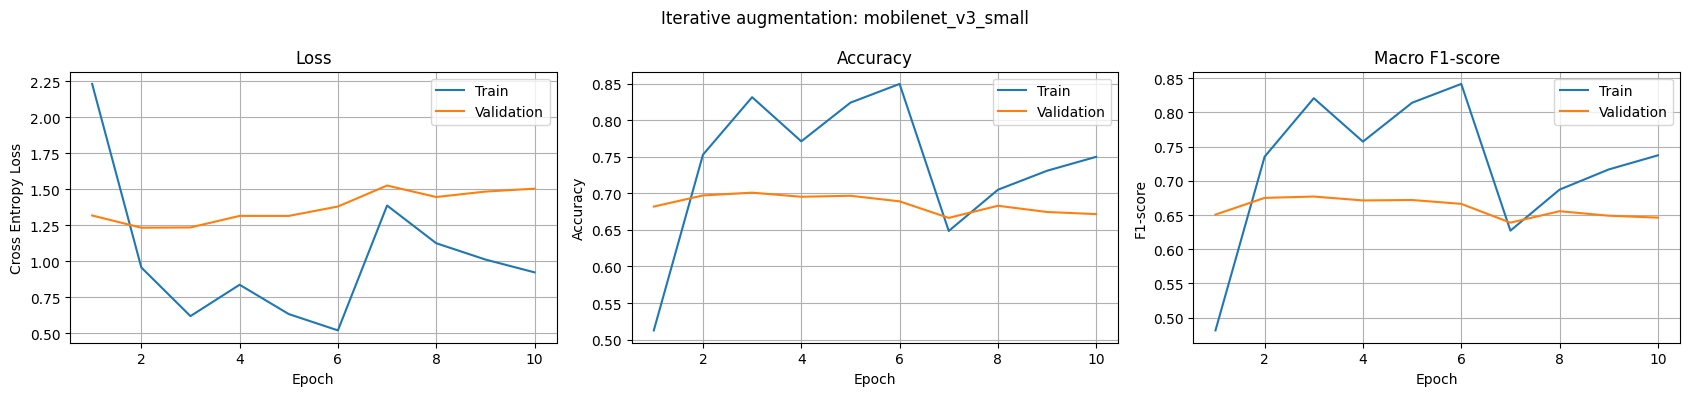

In [13]:
iter_aug_results[mobilenet_name] = run_baseline_experiment(
    model_name=mobilenet_name,
    settings=MODEL_SETTINGS[mobilenet_name],
    config=baseline_config,
    aug_stages=AUG_STAGES,
    experiment_prefix="iter_aug_local",
    title_prefix="Iterative augmentation",
)

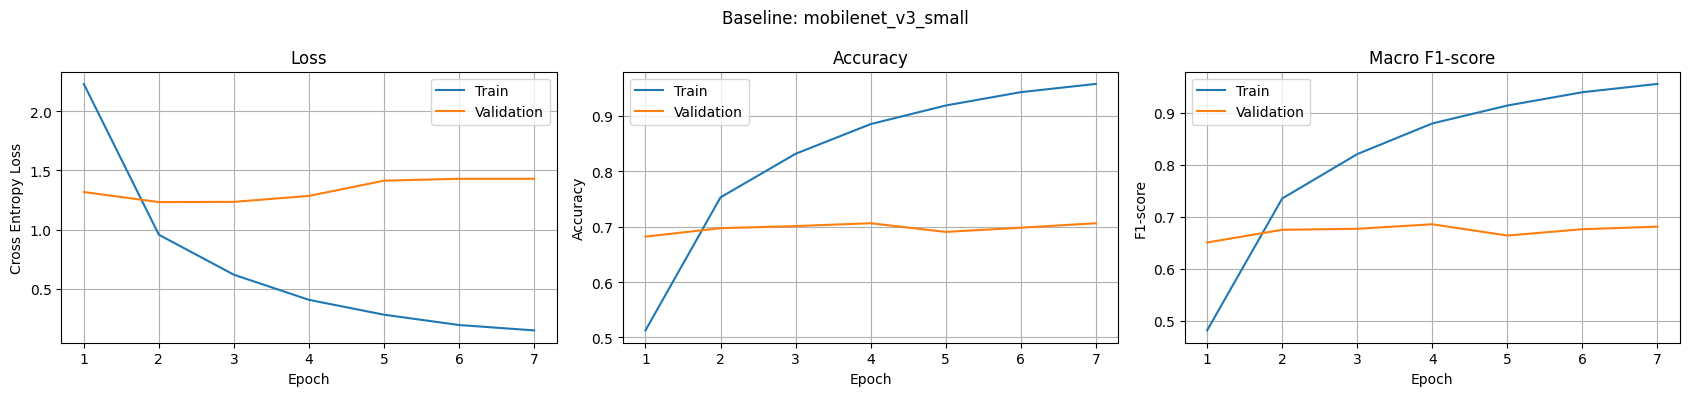

,val_loss,val_accuracy,val_macro_f1,val_weighted_f1,test_loss,test_accuracy,test_macro_f1,test_weighted_f1,train_minutes,epochs_run
Model,,,,,,,,,,
mobilenet_v3_small | baseline,1.285354,0.706067,0.685663,0.707451,1.295513,0.704790,0.684898,0.706195,38.406336,7.0
mobilenet_v3_small | iter_aug,1.235104,0.700918,0.676971,0.698994,1.252666,0.697851,0.675995,0.696309,72.251589,10.0


In [14]:
plot_history(
    baseline_results[mobilenet_name].history,
    title_prefix=f"Baseline: {mobilenet_name}",
)
display(
    build_comparison_table(
        {
            f"{mobilenet_name} | baseline": baseline_results[mobilenet_name],
            f"{mobilenet_name} | iter_aug": iter_aug_results[mobilenet_name],
        }
    )
)

**Сравнивая бейзлайн и применение итеративной аугментации, видно, что**:
- графики на train сильно скачут между стадиями (особенно после 3-й и 6-й эпох); усиление аугментации ожидаемо усложняет задачу для модели
- по итоговым метрикам итеративная аугментация немного уступает бейзлайну; разница небольшая, и ее можно считать в пределах шума, но улучшения техника не дала
- наилучший чекпоинт (эпоха 3) показывает val_macro_f1 = 0.6770, что близко к бейзлайну (0.6857), то есть на ранних эпохах качество сопоставимо
- применение техники не убрало переобучение; вероятно, из-за слишком сильной аугментации в level=2 при относительно небольшом числе эпох

#### ShuffleNetV2 x1.0


shufflenet_v2_x1_0: batch_size=64, channels_last=True, epochs=10, train batches=326

Augmentation stage 1/3: level=0, epochs=3

Epoch [1/3] (global epoch 1)
Train | Loss: 4.5000 | Accuracy: 0.1540 | Macro F1: 0.0892 | Weighted F1: 0.1122
Val   | Loss: 3.2361 | Accuracy: 0.3669 | Macro F1: 0.2593 | Weighted F1: 0.2965
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.2593

Epoch [2/3] (global epoch 2)
Train | Loss: 2.4262 | Accuracy: 0.5103 | Macro F1: 0.4525 | Weighted F1: 0.4783
Val   | Loss: 1.8323 | Accuracy: 0.5959 | Macro F1: 0.5430 | Weighted F1: 0.5725
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.5430

Epoch [3/3] (global epoch 3)
Train | Loss: 1.5002 | Accuracy: 0.6736 | Macro F1: 0.6379 | Weighted F1: 0.6604
Val   | Loss: 1.4429 | Accuracy: 0.6624 | Macro F1: 0.6237 | Weighted F1: 0.6505
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6237

Training finished
Best Val Macro F1: 0.6237
Be

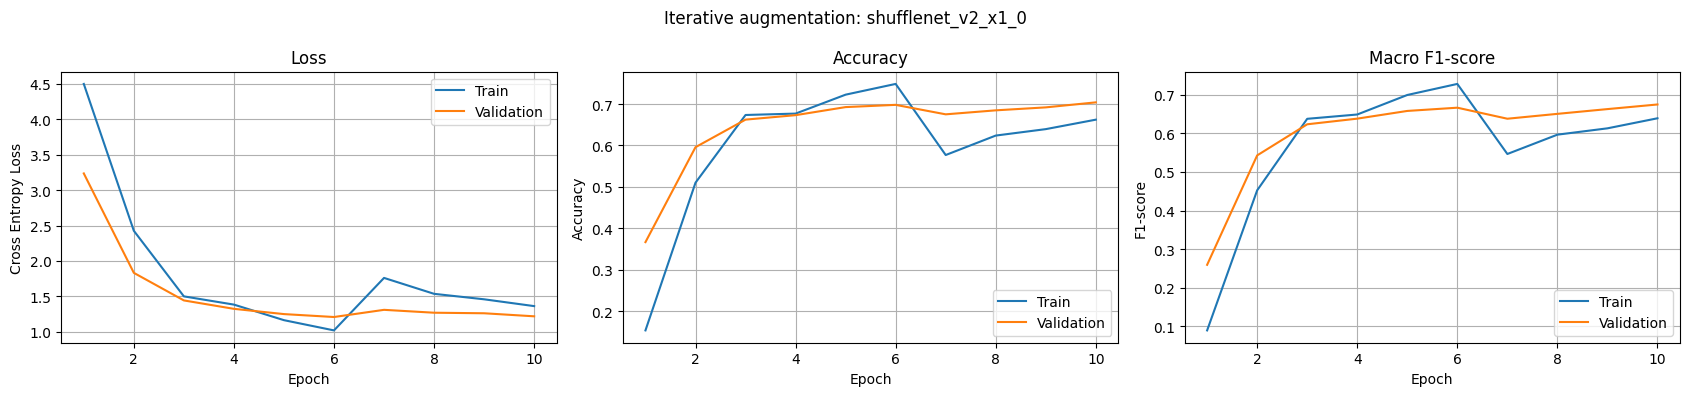

In [16]:
iter_aug_results[shufflenet_name] = run_baseline_experiment(
    model_name=shufflenet_name,
    settings=MODEL_SETTINGS[shufflenet_name],
    config=baseline_config,
    aug_stages=AUG_STAGES,
    experiment_prefix="iter_aug_local",
    title_prefix="Iterative augmentation",
)

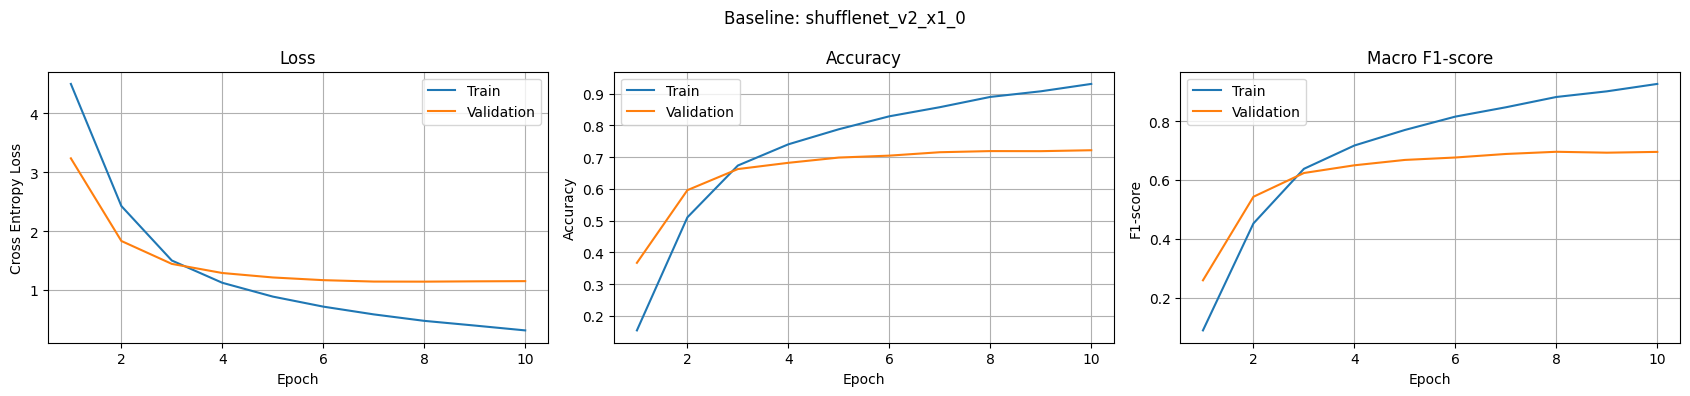

,val_loss,val_accuracy,val_macro_f1,val_weighted_f1,test_loss,test_accuracy,test_macro_f1,test_weighted_f1,train_minutes,epochs_run
Model,,,,,,,,,,
shufflenet_v2_x1_0 | baseline,1.141420,0.719051,0.695798,0.717463,1.192040,0.714637,0.691546,0.712125,89.695192,10.0
shufflenet_v2_x1_0 | iter_aug,1.218628,0.704052,0.675080,0.698418,1.253117,0.692480,0.664806,0.688212,94.497637,10.0


In [17]:
plot_history(
    baseline_results[shufflenet_name].history,
    title_prefix=f"Baseline: {shufflenet_name}",
)
display(
    build_comparison_table(
        {
            f"{shufflenet_name} | baseline": baseline_results[shufflenet_name],
            f"{shufflenet_name} | iter_aug": iter_aug_results[shufflenet_name],
        }
    )
)

**Сравнивая бейзлайн и применение итеративной аугментации, видно, что**:
- графики на train тоже скачут на переходе к level=1 и особенно к level=2, что ожидаемо при усложнении аугментации
- итоговые метрики немного ниже бейзлайна
- итеративная аугментация не дала прироста; модель осталась примерно на уровне бейзлайна

## Итеративная разморозка слоев с адаптиваным lr

Разморозка: head $\to$ late $\to$ mid $\to$ early за 2 + 3 + 3 + 2 = 10 эпох.

In [20]:
unfreeze_results = {}

#### MobileNetV3-Small


mobilenet_v3_small: batch_size=64, channels_last=True, stages=[('head', 2), ('late', 3), ('mid', 3), ('early', 2)], total epochs=10 (baseline: 10)

Unfreezing stage 1/4: +head (lr=1e-03), epochs=2, trainable params=853,248

Epoch [1/2] (global epoch 1)
Train | Loss: 2.0876 | Accuracy: 0.5438 | Macro F1: 0.5161 | Weighted F1: 0.5342
Val   | Loss: 1.3260 | Accuracy: 0.6812 | Macro F1: 0.6520 | Weighted F1: 0.6739
head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6520

Epoch [2/2] (global epoch 2)
Train | Loss: 0.9186 | Accuracy: 0.7659 | Macro F1: 0.7501 | Weighted F1: 0.7640
Val   | Loss: 1.2456 | Accuracy: 0.6906 | Macro F1: 0.6682 | Weighted F1: 0.6895
head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6682

Training finished
Best Val Macro F1: 0.6682
Best checkpoint: d:\repos\applied-ml\hw1\data\checkpoints\unfreeze_local_mobilenet_v3_small_best.pt
History: d:\repos\applied-ml\hw1\data\checkpoints\unfreeze_local_mobilenet_v3_small_history.json

Unfreezing stage 2/4: +late (lr

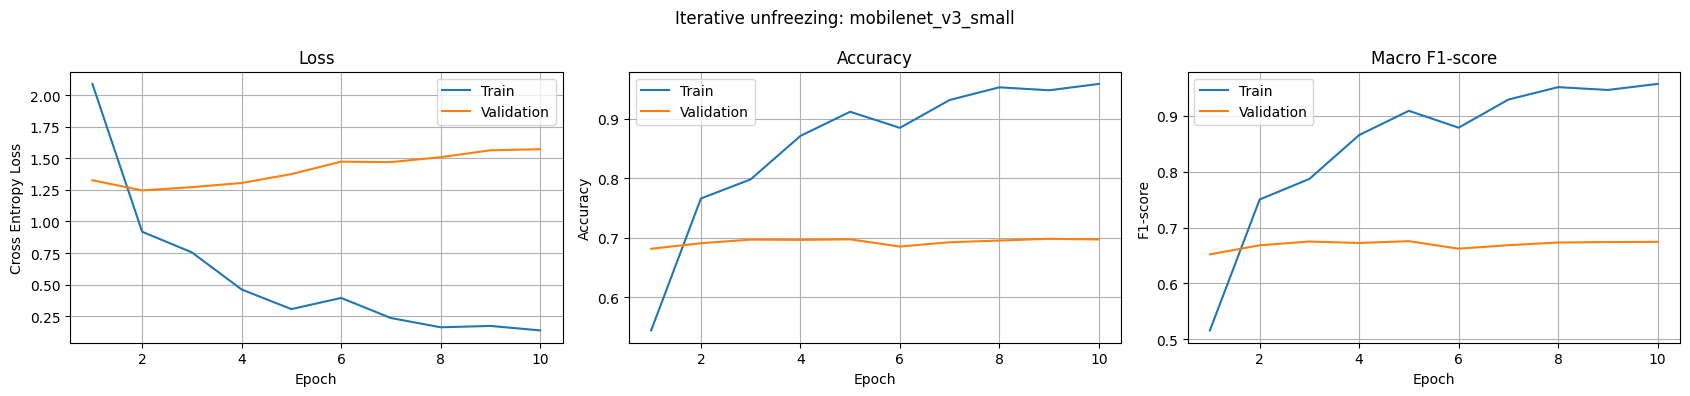

In [21]:
unfreeze_results[mobilenet_name] = run_unfreeze_experiment(
    model_name=mobilenet_name,
    settings=MODEL_SETTINGS[mobilenet_name],
    config=baseline_config,
    stages=UNFREEZE_STAGES,
    lr_factor=10.0,
    experiment_prefix="unfreeze_local",
)

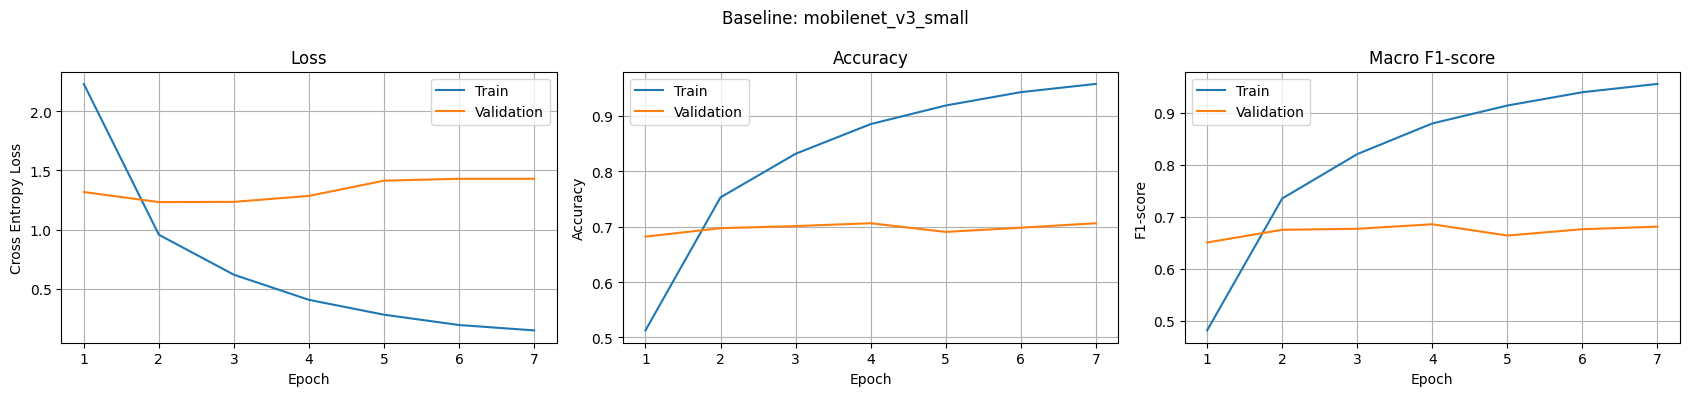

,val_loss,val_accuracy,val_macro_f1,val_weighted_f1,test_loss,test_accuracy,test_macro_f1,test_weighted_f1,train_minutes,epochs_run
Model,,,,,,,,,,
mobilenet_v3_small | baseline,1.285354,0.706067,0.685663,0.707451,1.295513,0.704790,0.684898,0.706195,38.406336,7.0
mobilenet_v3_small | unfreeze,1.374442,0.697112,0.675629,0.697805,1.384592,0.700537,0.677589,0.700308,33.386410,10.0


In [22]:
plot_history(
    baseline_results[mobilenet_name].history,
    title_prefix=f"Baseline: {mobilenet_name}",
)
display(
    build_comparison_table(
        {
            f"{mobilenet_name} | baseline": baseline_results[mobilenet_name],
            f"{mobilenet_name} | unfreeze": unfreeze_results[mobilenet_name],
        }
    )
)

**Сравнивая бейзлайн и применение итеративной разморозки, видно, что**:
- переобучение стало выраженнее; разрыв между train и val больше, чем в бейзлайне
- метрики немного хуже бейзлайна
- лучший чекпоинтбыл  достигнут уже на 5-й эпохе (вторая стадия), а после разморозки mid- и early-слоев метрики на Val перестают расти, а val loss стабильно увеличивается; скорее всего, дополнительные слои дали модели запомнить обучающую выборку
- при этом графики на trainотносительно предыдущего метода более гладкие и без сильных скачков

#### ShuffleNetV2 x1.0


shufflenet_v2_x1_0: batch_size=64, channels_last=True, stages=[('head', 2), ('late', 3), ('mid', 3), ('early', 2)], total epochs=10 (baseline: 10)

Unfreezing stage 1/4: +head (lr=1e-03), epochs=2, trainable params=262,400

Epoch [1/2] (global epoch 1)
Train | Loss: 5.0137 | Accuracy: 0.0746 | Macro F1: 0.0189 | Weighted F1: 0.0423
Val   | Loss: 4.5644 | Accuracy: 0.1439 | Macro F1: 0.0656 | Weighted F1: 0.0987
head LR: 1.00e-03
Best model updated. Val Macro F1: 0.0656

Epoch [2/2] (global epoch 2)
Train | Loss: 4.1699 | Accuracy: 0.2615 | Macro F1: 0.2105 | Weighted F1: 0.2355
Val   | Loss: 3.8770 | Accuracy: 0.3642 | Macro F1: 0.3147 | Weighted F1: 0.3321
head LR: 1.00e-03
Best model updated. Val Macro F1: 0.3147

Training finished
Best Val Macro F1: 0.3147
Best checkpoint: d:\repos\applied-ml\hw1\data\checkpoints\unfreeze_local_shufflenet_v2_x1_0_best.pt
History: d:\repos\applied-ml\hw1\data\checkpoints\unfreeze_local_shufflenet_v2_x1_0_history.json

Unfreezing stage 2/4: +late (lr

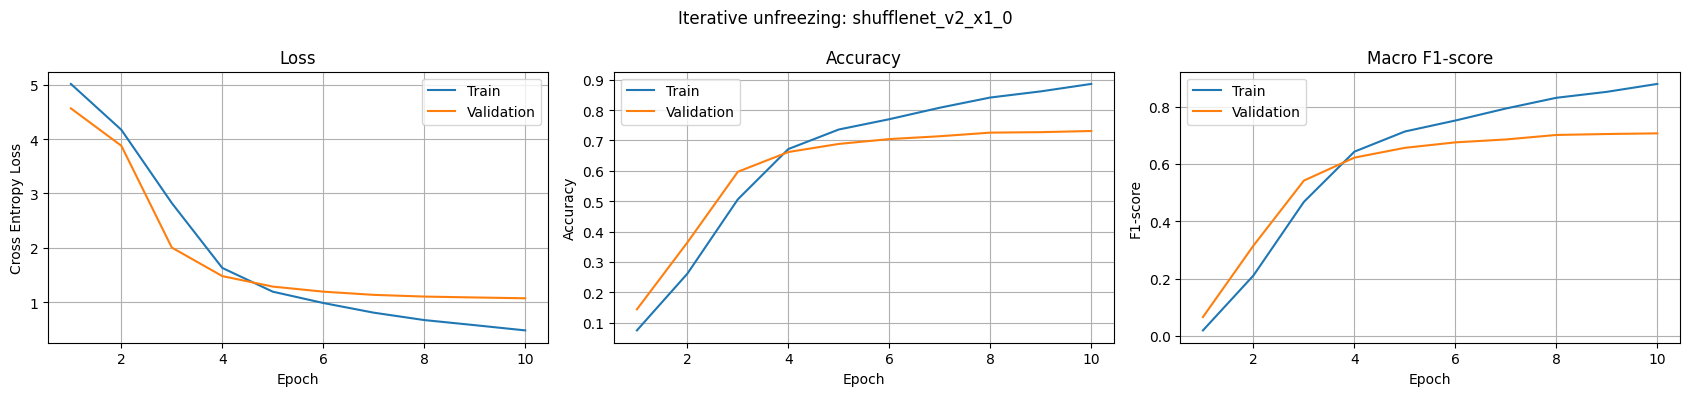

In [24]:
unfreeze_results[shufflenet_name] = run_unfreeze_experiment(
    model_name=shufflenet_name,
    settings=MODEL_SETTINGS[shufflenet_name],
    config=baseline_config,
    stages=UNFREEZE_STAGES,
    lr_factor=10.0,
    experiment_prefix="unfreeze_local",
)

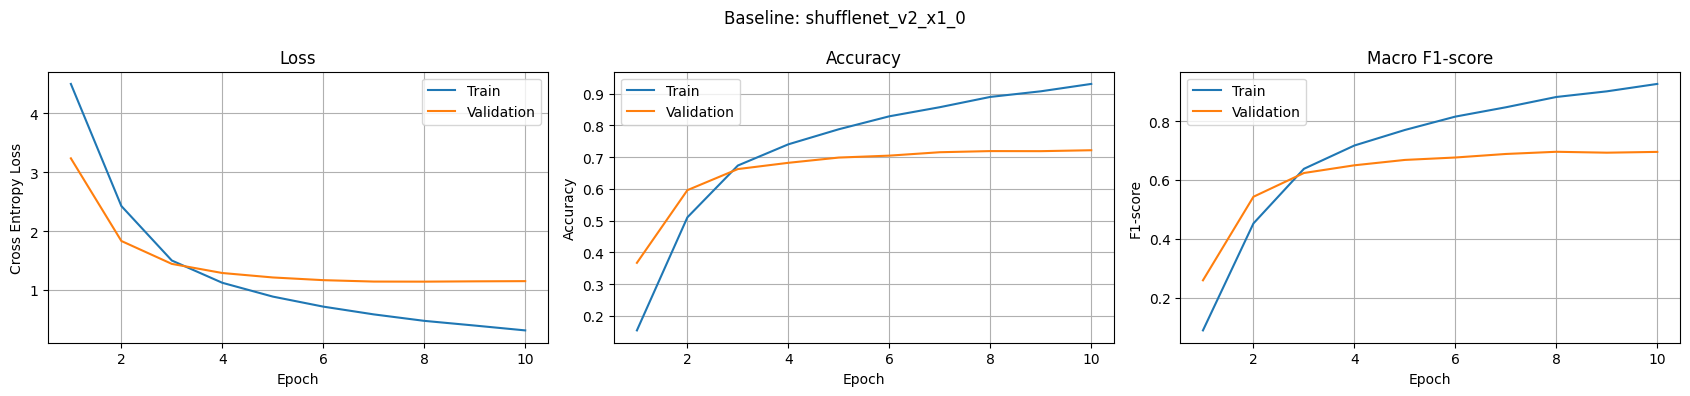

,val_loss,val_accuracy,val_macro_f1,val_weighted_f1,test_loss,test_accuracy,test_macro_f1,test_weighted_f1,train_minutes,epochs_run
Model,,,,,,,,,,
shufflenet_v2_x1_0 | baseline,1.141420,0.719051,0.695798,0.717463,1.192040,0.714637,0.691546,0.712125,89.695192,10.0
shufflenet_v2_x1_0 | unfreeze,1.072362,0.731139,0.706701,0.726537,1.111668,0.724038,0.700849,0.721131,48.265192,10.0


In [ ]:
plot_history(
    baseline_results[shufflenet_name].history,
    title_prefix=f"Baseline: {shufflenet_name}",
)
display(
    build_comparison_table(
        {
            f"{shufflenet_name} | baseline": baseline_results[shufflenet_name],
            f"{shufflenet_name} | unfreeze": unfreeze_results[shufflenet_name],
        }
    )
)

**Сравнивая бейзлайн и применение итеративной разморозки слоев, видно, что**:
- это единственная техника, которая немного улучшила значения метрик и функций потерь
- качество растет вместе с увеличением разрыва на train/val (то есть переобучение), но в отличие от MobileNet увеличивается и обобщающая способность
- также обучение заняло почти вдвое меньше времени, чем бейзлайн (90 мин и 48 мин)

## Псевдолейблинг

Уже обученный бейзлайн соответствующей модели предсказывает метки для изображений test. Истинные метки test при обучении не используются.

Новая модель с весами ImageNet обучается на train + test с псевдометками.

In [28]:
pseudo_results = {}

#### MobileNetV3-Small


Loaded checkpoint from epoch 4

Pseudo-labeling: 2292 of 4468 test images (51.3%) passed threshold 0.90

mobilenet_v3_small: batch_size=64, channels_last=True, epochs=10, train batches=362

Epoch [1/10] (global epoch 1)
Train | Loss: 2.0230 | Accuracy: 0.5584 | Macro F1: 0.5202 | Weighted F1: 0.5490
Val   | Loss: 1.3240 | Accuracy: 0.6709 | Macro F1: 0.6400 | Weighted F1: 0.6664
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6400

Epoch [2/10] (global epoch 2)
Train | Loss: 0.8680 | Accuracy: 0.7720 | Macro F1: 0.7495 | Weighted F1: 0.7700
Val   | Loss: 1.2791 | Accuracy: 0.6832 | Macro F1: 0.6588 | Weighted F1: 0.6815
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.6588

Epoch [3/10] (global epoch 3)
Train | Loss: 0.5681 | Accuracy: 0.8423 | Macro F1: 0.8288 | Weighted F1: 0.8416
Val   | Loss: 1.2809 | Accuracy: 0.7016 | Macro F1: 0.6793 | Weighted F1: 0.7006
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val 

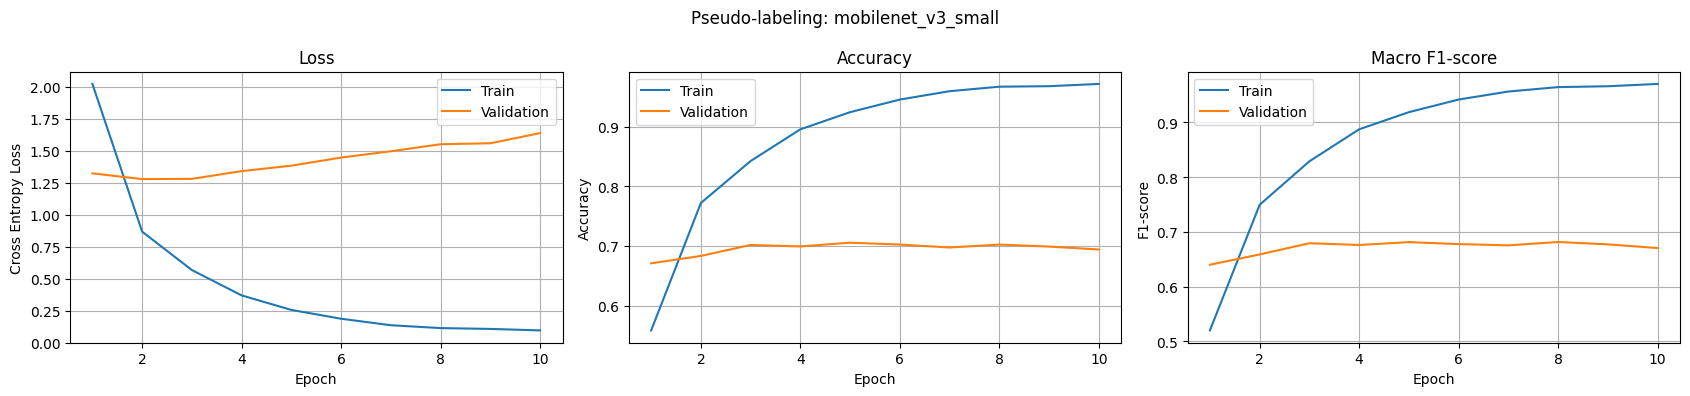

In [29]:
pseudo_results[mobilenet_name] = run_pseudo_label_experiment(
    model_name=mobilenet_name,
    settings=MODEL_SETTINGS[mobilenet_name],
    config=baseline_config,
    confidence_threshold=PSEUDO_CONFIDENCE_THRESHOLD,
    experiment_prefix="pseudo_local",
)

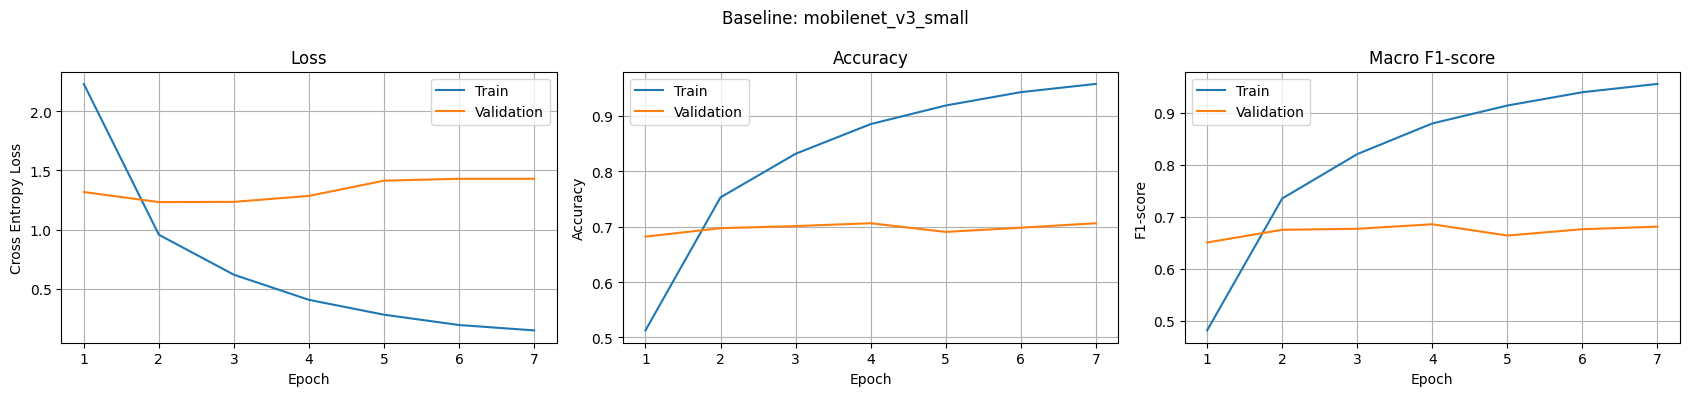

,val_loss,val_accuracy,val_macro_f1,val_weighted_f1,test_loss,test_accuracy,test_macro_f1,test_weighted_f1,train_minutes,epochs_run
Model,,,,,,,,,,
mobilenet_v3_small | baseline,1.285354,0.706067,0.685663,0.707451,1.295513,0.704790,0.684898,0.706195,38.406336,7.0
mobilenet_v3_small | pseudo,1.551620,0.702261,0.681524,0.702629,1.650972,0.707252,0.686193,0.705904,52.436168,10.0


In [30]:
plot_history(
    baseline_results[mobilenet_name].history,
    title_prefix=f"Baseline: {mobilenet_name}",
)
display(
    build_comparison_table(
        {
            f"{mobilenet_name} | baseline": baseline_results[mobilenet_name],
            f"{mobilenet_name} | pseudo": pseudo_results[mobilenet_name],
        }
    )
)

**Сравнивая бейзлайн и применение псевдолейблинга, видно, что**:
- 51.3% тестовых изображений прошли порог уверенности 0.9 и были добавлены в обучение (умеренный прирост данных)
- метрики на val немного хуже бейзлайна, а на test даже незначительно выросли
- самый сильный разрыв train/val среди всех экспериментов: функция потерь на train падает до 0.096, train accuracy равна 0.97 при val accuracy 0.7; псевдолейблинг усилил переобучение, так как, вероятно, часть добавленных псевдометок содержила ошибки, и модель начала подгоняться и под них
- в целом техника дала результат, близкий к бейзлайну

#### ShuffleNetV2 x1.0

Loaded checkpoint from epoch 8

Pseudo-labeling: 1817 of 4468 test images (40.7%) passed threshold 0.90

shufflenet_v2_x1_0: batch_size=64, channels_last=True, epochs=10, train batches=355

Epoch [1/10] (global epoch 1)
Train | Loss: 4.3455 | Accuracy: 0.1844 | Macro F1: 0.1104 | Weighted F1: 0.1403
Val   | Loss: 3.0001 | Accuracy: 0.3944 | Macro F1: 0.2906 | Weighted F1: 0.3280
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.2906

Epoch [2/10] (global epoch 2)
Train | Loss: 2.1526 | Accuracy: 0.5644 | Macro F1: 0.4981 | Weighted F1: 0.5332
Val   | Loss: 1.7292 | Accuracy: 0.6087 | Macro F1: 0.5515 | Weighted F1: 0.5840
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val Macro F1: 0.5515

Epoch [3/10] (global epoch 3)
Train | Loss: 1.3292 | Accuracy: 0.7061 | Macro F1: 0.6645 | Weighted F1: 0.6941
Val   | Loss: 1.3986 | Accuracy: 0.6620 | Macro F1: 0.6210 | Weighted F1: 0.6494
backbone LR: 1.00e-04 | head LR: 1.00e-03
Best model updated. Val 

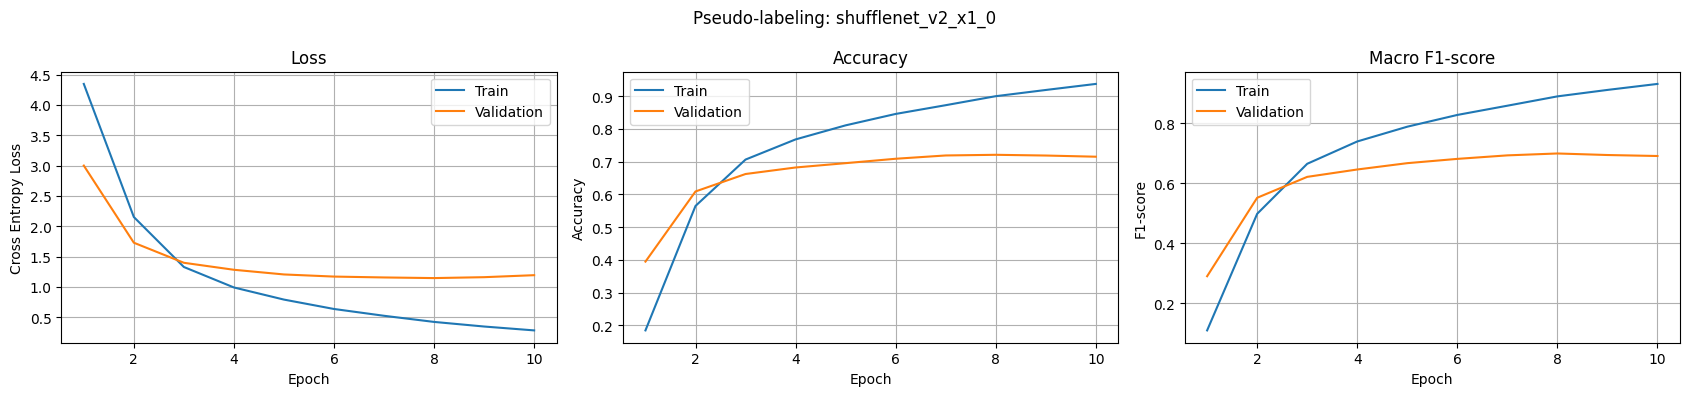

In [31]:
pseudo_results[shufflenet_name] = run_pseudo_label_experiment(
    model_name=shufflenet_name,
    settings=MODEL_SETTINGS[shufflenet_name],
    config=baseline_config,
    confidence_threshold=PSEUDO_CONFIDENCE_THRESHOLD,
    experiment_prefix="pseudo_local",
)

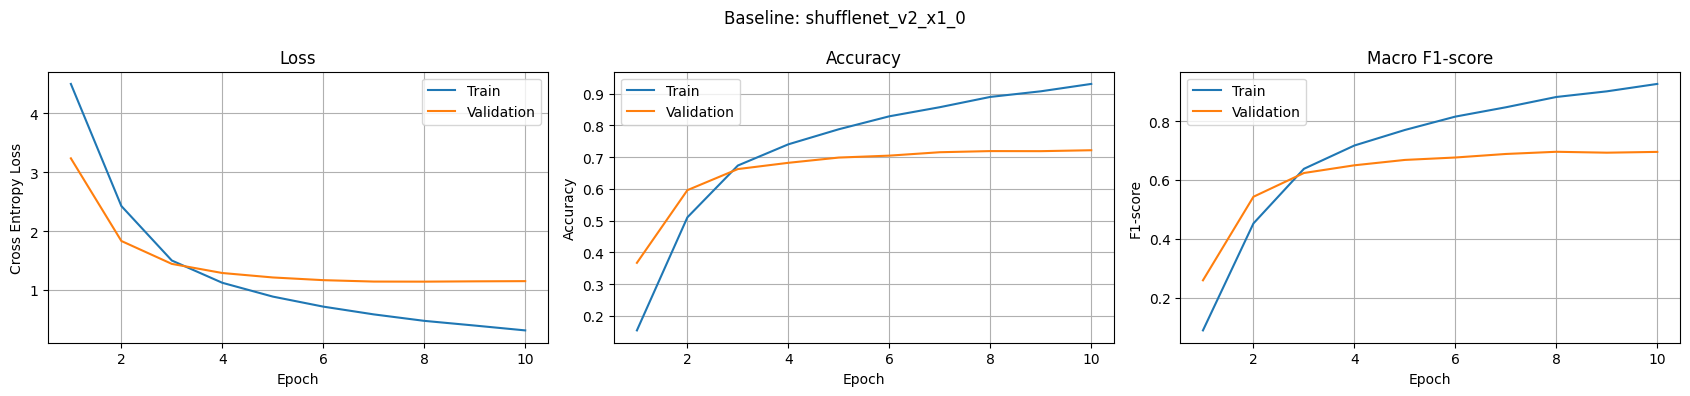

,val_loss,val_accuracy,val_macro_f1,val_weighted_f1,test_loss,test_accuracy,test_macro_f1,test_weighted_f1,train_minutes,epochs_run
Model,,,,,,,,,,
shufflenet_v2_x1_0 | baseline,1.141420,0.719051,0.695798,0.717463,1.192040,0.714637,0.691546,0.712125,89.695192,10.0
shufflenet_v2_x1_0 | pseudo,1.146485,0.720618,0.698835,0.719015,1.194804,0.709042,0.683189,0.706272,78.966261,10.0


In [32]:
plot_history(
    baseline_results[shufflenet_name].history,
    title_prefix=f"Baseline: {shufflenet_name}",
)
display(
    build_comparison_table(
        {
            f"{shufflenet_name} | baseline": baseline_results[shufflenet_name],
            f"{shufflenet_name} | pseudo": pseudo_results[shufflenet_name],
        }
    )
)

**Сравнивая бейзлайн и применение псевдолейблинга, видно, что**:
- через порог уверенности 0.9 прошло только 40.7% тестовых изображений — учитель (бейзлайн ShuffleNet) был менее уверен в предсказаниях, чем MobileNet
- результат получился неоднозначным: на валидации метрики чуть лучше бейзлайна, а на тесте чуть хуже
- кривые обучения плавные, без скачков, при этом к концу виден растущий разрыв train/val, то есть есть переобучение как в бейзлайне
- вероятно, ограничивающим фактором стало качество самого учителя: с accuracy 0.72 даже уверенные предсказания содержат заметную долю ошибок, поэтому добавление новых данных оказалось примерно сопоставимо с шумом, и качество практически совпало с бейзлайном

## Вывод

Во всех прогонах, включая бейзлайн, заметен устойчивый разрыв между метриками на train и val (train accuracy доходит до 0.9–0.97 при val accuracy 0.70–0.73), то есть переобучение присутствует уже в бейзлайне. Техники вели себя по-разному относительно этого разрыва: итеративная аугментация и псевдолейблинг увеличивали разрыв (особенно сильно псевдолейблинг на MobileNet), а разморозка на ShuffleNet показала единственный устойчивый прирост качества несмотря на рост разрыва train/val. В общем, на датасете Caltech-256 с 256 сильно несбалансированными классами основной выигрыш дала плавная и долгая настройка предобученной backbone при малых learning rate.